# Cost-Effectiveness — The Cost of Medicaid Expansion per Newly Insured Person

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** CMS-64 file of 2026-02-17 and ACS 2012–2019 1-year PUMS

This notebook uses **real data only**. There is no synthetic generator and no fallback. The effect comes from a
difference-in-differences on weighted PUMS cells (no person-level row is read, printed or stored); the cost comes from a
committed copy of the CMS file, checked against its recorded digest.

The analysis was fixed in a written plan (`pap/E01_plan.md`) committed before the expenditure table was built or any
expenditure amount was read. The notebook is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Define** a cost-effectiveness ratio as cost per unit of effect against a comparator, and say what the comparator is here
   (no expansion).
2. **Build** the numerator from a government expenditure file, with its negative adjustments, blanks and zeros read as they
   are and not repaired.
3. **Build** the denominator from a causal estimate, and see why the population the cost covers and the population the effect
   covers have to be the same.
4. **Propagate** uncertainty from the effect and from a range of costs into a ratio, and read a cost-effectiveness
   acceptability curve.
5. **State** which offsets the gross cost omits and in which direction that biases the ratio.

## Prerequisites

**Knowledge.** The difference-in-differences design of C01; what an incremental cost-effectiveness ratio is; weighted least squares.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the environment variable
`CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`. The key is read at
runtime and is never printed or written into this notebook's output. The retrieval makes 280 requests and takes several minutes.
The cost file is committed in the repository and needs no key.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package (`methods.cea`
and `methods.iv`).

**Prior notebooks.** C01 supplies the design and the comparison estimate; C06 supplies the state-by-year PUMS cells.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `expansion_expenditure.csv` | CMS, *Medicaid CMS-64 New Adult Group Expenditures* (data.medicaid.gov), through `data/policy/medicaid/`; digest and transformation in its `SOURCES.md` | cost (numerator) |
| `HICOV`, `AGEP` | ACS 2012–2019 1-year PUMS, weighted cells only | newly insured persons (denominator) |
| `data/policy/medicaid/expansion_dates.csv` | KFF expansion status | treated and control states |
| C01's stored output | `projects/09-causal-identification/C01_medicaid_expansion_did/` | cross-check ATT, ages 35–64 |

Each PUMS request is recorded in `provenance/`, bound to the plan's SHA-256.

> **A mismatch that matters.** The CMS spending covers the whole expansion population, adults 19 to 64. C01's ATT is for ages
> 35 to 64 only, because the ACS table it uses has no consistent 19–64 series. Dividing a 19–64 cost by a 35–64 effect would
> overstate the cost per person, so the headline here applies C01's design to ages 19 to 64 (PUMS has single years of age, so
> there is no band change). C01's own ATT is shown beside it, and a second, labelled upper bound counts only the 35–64 effect.

## Design and identification

**Estimand.** Gross public spending per newly insured person-year, for the 25 states whose expansion took effect on 1 January 2014,
over 2014 to 2019, against no expansion. The comparator is the never-expanded states.

**Effect.** The same difference-in-differences as C01, on the share of adults 19 to 64 with no health insurance, weighted by
population, with state and year effects, clustered by state. It rests on C01's parallel-trends argument.

**Rule, fixed in the plan.** The ratio is reported as an interval only if the 95% interval of the effect excludes zero; otherwise the
cost per person is not bounded and the notebook says so.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import re
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import cea, iv
from krl_tutorials_data.sources import DataAccessError, fetch_acs_pums

NB_DIR = REPO_ROOT / "projects" / "10-economic-evaluation" / "E01_cost_per_newly_insured"
PLAN = NB_DIR / "pap" / "E01_plan.md"
PLAN_SHA256 = hashlib.sha256(PLAN.read_bytes()).hexdigest()
C01_NOTEBOOK = (REPO_ROOT / "projects" / "09-causal-identification" / "C01_medicaid_expansion_did"
                / "C01_medicaid_expansion_did.ipynb")

YEARS = list(range(2012, 2020))
POST = [y for y in YEARS if y >= 2014]
N_DRAWS, SEED = 20_000, 20261023
THRESHOLDS = np.arange(1_000, 30_001, 1_000)

print(f"plan              : {PLAN.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PLAN_SHA256}")
print(f"years             : {YEARS[0]}-{YEARS[-1]}; post-period {POST[0]}-{POST[-1]}")

plan              : projects/10-economic-evaluation/E01_cost_per_newly_insured/pap/E01_plan.md
plan SHA-256      : b4a11856be095640088c46fc7ad48e77d4635b6db046c3d88b8cf3e66fbfbabb
years             : 2012-2019; post-period 2014-2019


### The states

Treated: expansion effective 1 January 2014 (the states of C01 and C06). Control: states that never expanded. Others are excluded.

In [2]:
policy = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")
policy["group"] = np.select(
    [policy["expansion_effective"] == "2014-01-01", policy["status"] == "Not Adopted"],
    ["treated", "control"], default="excluded",
)
print(policy["group"].value_counts().to_string())
TREATED = policy.loc[policy["group"] == "treated", "state"].tolist()

reply = requests.get("https://www2.census.gov/geo/docs/reference/state.txt", timeout=60,
                     headers={"User-Agent": "telosyn-notebooks/1.0"})
reply.raise_for_status()
codes = pd.read_csv(io.StringIO(reply.text), sep="|", dtype=str)
fips = dict(zip(codes["STATE_NAME"], codes["STATE"]))
states = policy[policy["group"] != "excluded"].assign(fips=lambda d: d["state"].map(fips))
assert states["fips"].notna().all() and len(states) == 35

group
treated     25
excluded    16
control     10


### The cost: summed from the committed table

The CMS file is committed unchanged with a digest, and a script turns it into a tidy table. Here its spending on the expansion population
("VIII Group") is summed over the treated states and the quarters ending 2014-03-31 to 2019-12-31. Blank, `N/A` and zero quarters are
counted as unreported and not imputed; negative quarters are prior-period adjustments and are kept.

In [3]:
spend = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_expenditure.csv", dtype={"note": str})
spend["quarter_end"] = pd.to_datetime(spend["quarter_end"])
window = spend[spend["state"].isin(TREATED) & (spend["quarter_end"] >= "2014-03-31") & (spend["quarter_end"] <= "2019-12-31")].copy()
print(f"treated state-quarters in the window: {len(window)} ({window['state'].nunique()} states x {window['quarter_end'].nunique()} quarters)")

unreported = window[window["viii_computable"].isna() | (window["viii_computable"] == 0)]
print(f"state-quarters with a blank, N/A or zero VIII Group total (unreported, not imputed): {len(unreported)}")
if len(unreported):
    print(unreported.groupby("state").size().sort_values(ascending=False).head(8).to_string())

COLUMNS = {"headline": "viii_computable", "federal share": "viii_federal",
           "lower (newly eligible only)": "viii_newly_eligible_computable"}
totals = {name: float(window[col].sum(skipna=True)) for name, col in COLUMNS.items()}
by_year = window.assign(year=window["quarter_end"].dt.year).groupby("year")[list(COLUMNS.values())].sum()
by_year.columns = list(COLUMNS)
print()
print((by_year / 1e9).round(2).to_string(float_format=lambda v: f"{v:,.2f}"), "  (billions of nominal dollars)")
for name, value in totals.items():
    print(f"{name:30s}: ${value / 1e9:,.2f} billion over {len(POST)} years")

treated state-quarters in the window: 600 (25 states x 24 quarters)
state-quarters with a blank, N/A or zero VIII Group total (unreported, not imputed): 0

      headline  federal share  lower (newly eligible only)
year                                                      
2014     44.26          41.52                        33.46
2015     62.17          58.17                        47.19
2016     77.82          73.71                        60.41
2017     77.53          70.46                        58.63
2018     80.04          72.33                        59.89
2019     82.33          74.33                        61.65   (billions of nominal dollars)
headline                      : $424.15 billion over 6 years
federal share                 : $390.51 billion over 6 years
lower (newly eligible only)   : $321.24 billion over 6 years


In [4]:
"""Checks on the cost table, stored as CHECK lines."""
parts = window.dropna(subset=["viii_computable", "viii_newly_eligible_computable", "viii_not_newly_eligible_computable"])
gap = (parts["viii_computable"] - parts["viii_newly_eligible_computable"] - parts["viii_not_newly_eligible_computable"]).abs()
RECONCILES = bool((gap <= 1).all())
print(f"CHECK: newly plus not-newly eligible equals the VIII Group total within one dollar | rows checked={len(parts)} | largest gap {gap.max():.0f} dollars | verdict={'PASS' if RECONCILES else 'FAIL'}")
annual = window.assign(year=window["quarter_end"].dt.year).groupby(["state", "year"])["viii_computable"].sum(min_count=1)
NO_NEGATIVE_YEAR = bool((annual.dropna() >= 0).all())
print(f"CHECK: no treated state has a negative annual VIII Group total | state-years={annual.notna().sum()} | most negative {annual.min():,.0f} dollars | verdict={'PASS' if NO_NEGATIVE_YEAR else 'FAIL'}")
negative = int((window[["viii_computable", "viii_newly_eligible_computable", "viii_not_newly_eligible_computable"]] < 0).sum().sum())
print(f"(negative quarterly cells kept as reported in the window: {negative})")

CHECK: newly plus not-newly eligible equals the VIII Group total within one dollar | rows checked=600 | largest gap 0 dollars | verdict=PASS
CHECK: no treated state has a negative annual VIII Group total | state-years=150 | most negative 143,647,562 dollars | verdict=PASS
(negative quarterly cells kept as reported in the window: 45)


### The effect: C01's design on ages 19 to 64, from weighted cells

One request per state and year. Each reads the state's records for adults aged 19 to 64 and aggregates them to weighted cells by age band
(19–34 and 35–64) and insurance status; no person row is returned.

In [5]:
def published_labels(year: int, wanted: tuple[str, ...]) -> dict[str, str]:
    """The label the Census Bureau publishes for each variable in this vintage."""
    for attempt in range(4):
        try:
            listing = requests.get(f"https://api.census.gov/data/{year}/acs/acs1/pums/variables.json", timeout=180)
            listing.raise_for_status()
            return {c: listing.json()["variables"][c]["label"] for c in wanted}
        except requests.RequestException:
            clock.sleep(10 * (attempt + 1))
    raise SystemExit(f"The variables list for {year} could not be read.")


parts, withheld, kept = [], 0, 0
try:
    for year in YEARS:
        variables = published_labels(year, ("AGEP", "HICOV"))
        for _, row in states.iterrows():
            frame, prov = fetch_acs_pums(
                year=year, variables=variables, aggregate_by=["AGEP", "HICOV"], geography=f"state:{row['fips']}",
                keep={"AGEP": (19, 64)}, bands={"AGEP": [19, 35, 65]},
            )
            frame["year"], frame["state"] = year, row["state"]
            parts.append(frame)
            withheld += int(frame.attrs["suppressed_records"])
            kept += int(frame.attrs["records_kept"])
            prov.with_pap(PLAN).write(NB_DIR / "provenance" / f"e01_pums{year}_{row['fips']}.json")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

cells = pd.concat(parts, ignore_index=True)
print(f"requests: {len(YEARS) * len(states)}; records kept {kept:,}; withheld by the 10-record floor {withheld:,} ({withheld / kept:.2%})")

requests: 280; records kept 11,479,721; withheld by the 10-record floor 0 (0.00%)


In [6]:
"""State-year panels: population and the uninsured share, for all adults 19-64 and for 35-64."""
cells["uninsured"] = cells["weighted_n"] * (cells["HICOV"] == 2)


def panel(ages: list[int]) -> pd.DataFrame:
    """One row per state and year, with the weighted population and the uninsured rate (per cent)."""
    sub = cells[cells["AGEP"].isin(ages)]
    out = sub.groupby(["state", "year"]).agg(pop=("weighted_n", "sum"), unins=("uninsured", "sum")).reset_index()
    out["rate"] = 100 * out["unins"] / out["pop"]
    out = out.merge(states[["state", "group"]], on="state")
    out["D"] = ((out["group"] == "treated") & (out["year"] >= 2014)).astype(float)
    return out


def estimate(frame: pd.DataFrame) -> iv.IvFit:
    """Population-weighted DiD: the regressor serves as its own instrument, so this is weighted OLS with clustered errors."""
    dummies = pd.concat([pd.get_dummies(frame[c], prefix=c, drop_first=True) for c in ("state", "year")], axis=1)
    return iv.tsls(frame["rate"], frame["D"], frame["D"], cluster=frame["state"],
                   controls=dummies.to_numpy(dtype=float), weights=frame["pop"])


p_all, p_35 = panel([19, 35]), panel([35])
fit_all, fit_35 = estimate(p_all), estimate(p_35)
t_crit = float(stats.t.ppf(0.975, fit_all.n_clusters - 1))


def show(label: str, fit: iv.IvFit) -> None:
    """One estimate with its interval."""
    print(f"{label:34s}: {fit.coef:+.3f} pp (SE {fit.se:.3f}), 95% interval [{fit.coef - t_crit * fit.se:+.3f}, {fit.coef + t_crit * fit.se:+.3f}]")


show("ages 19-64 (headline), PUMS", fit_all)
show("ages 35-64, PUMS", fit_35)
text = " ".join("".join(o["text"]) for cell in __import__("json").loads(C01_NOTEBOOK.read_text())["cells"]
                if cell["cell_type"] == "code" for o in cell.get("outputs", []) if o.get("output_type") == "stream")
att_c01 = float(re.search(r"ATT \(TWFE\)\s*:\s*([+-][\d.]+) pp", text).group(1))
se_c01 = float(re.search(r"cluster.{1,8}SE\s*:\s*([\d.]+)", text).group(1))
print(f"{'ages 35-64, C01 (ACS table), stored':34s}: {att_c01:+.3f} pp (SE {se_c01:.3f})")

ages 19-64 (headline), PUMS       : -2.112 pp (SE 1.354), 95% interval [-4.864, +0.639]
ages 35-64, PUMS                  : -1.814 pp (SE 1.244), 95% interval [-4.343, +0.715]
ages 35-64, C01 (ACS table), stored: -1.453 pp (SE 0.728)


In [7]:
"""Check: the sign of the 19-64 effect agrees with C01's."""
SIGN_AGREES = np.sign(fit_all.coef) == np.sign(att_c01)
print(f"CHECK: the 19-64 effect has the same sign as C01's stored ATT | statistic={fit_all.coef:.4f} | C01 {att_c01:+.4f} | verdict={'PASS' if SIGN_AGREES else 'FAIL'}")

CHECK: the 19-64 effect has the same sign as C01's stored ATT | statistic=-2.1124 | C01 -1.4530 | verdict=PASS


### Newly insured person-years

The effect is applied to the treated states' population each year. One average effect is used for every year, which the plan states as a
limitation.

In [8]:
pop_year = p_all[p_all["group"] == "treated"].groupby("year")["pop"].sum()
pop_35_year = p_35[p_35["group"] == "treated"].groupby("year")["pop"].sum()
pop_post = float(pop_year.loc[POST].sum())
person_years = -fit_all.coef / 100 * pop_post
person_years_se = fit_all.se / 100 * pop_post
newly = (-fit_all.coef / 100 * pop_year.loc[POST]).rename("newly insured")
table = pd.DataFrame({"population 19-64": pop_year.loc[POST], "newly insured": newly,
                      "spending": by_year["headline"].reindex(POST)})
table["cost per newly insured"] = table["spending"] / table["newly insured"]
print((table / [1e6, 1e6, 1e9, 1]).round(2).rename(columns={"population 19-64": "population 19-64 (m)", "newly insured": "newly insured (m)", "spending": "spending ($bn)"}).to_string(float_format=lambda v: f"{v:,.2f}"))
print()
print(f"person-years of coverage added, {POST[0]}-{POST[-1]}: {person_years / 1e6:,.2f} million (SE {person_years_se / 1e6:,.2f} million)")
lo_e, hi_e = person_years - t_crit * person_years_se, person_years + t_crit * person_years_se
print(f"95% interval of the person-years: [{lo_e / 1e6:,.2f}, {hi_e / 1e6:,.2f}] million")

      population 19-64 (m)  newly insured (m)  spending ($bn)  cost per newly insured
year                                                                                 
2014                 98.27               2.08           44.26               21,318.29
2015                 98.71               2.09           62.17               29,817.51
2016                 98.56               2.08           77.82               37,376.90
2017                 98.92               2.09           77.53               37,101.35
2018                 98.59               2.08           80.04               38,432.85
2019                 98.25               2.08           82.33               39,672.06

person-years of coverage added, 2014-2019: 12.49 million (SE 8.01 million)
95% interval of the person-years: [-3.78, 28.76] million


### The ratio, and its uncertainty

Cost per newly insured person-year is the headline cost over the person-years added. The probabilistic sensitivity draws the effect from a normal
distribution around its estimate with its standard error, and the cost from a normal distribution centred on the middle of the cost range with the
range read as its 95% interval, independently.

cost per newly insured person-year, headline: $33,957  (status: icer)
  headline                      : $33,957
  federal share                 : $31,265
  lower (newly eligible only)   : $25,718
  upper bound, counting only the 35-64 effect (19-64 cost over the 35-64 person-years): $77,629
draws: 20,000; seed 20261023; share of draws in which the effect is not positive: 0.0580
The 95% interval of the effect includes zero, so the cost per newly insured person is not bounded: the plan reports no interval.
probability that the spending is worth the added coverage reaches 50% at $30,000
probability does not reach 90% by $30,000


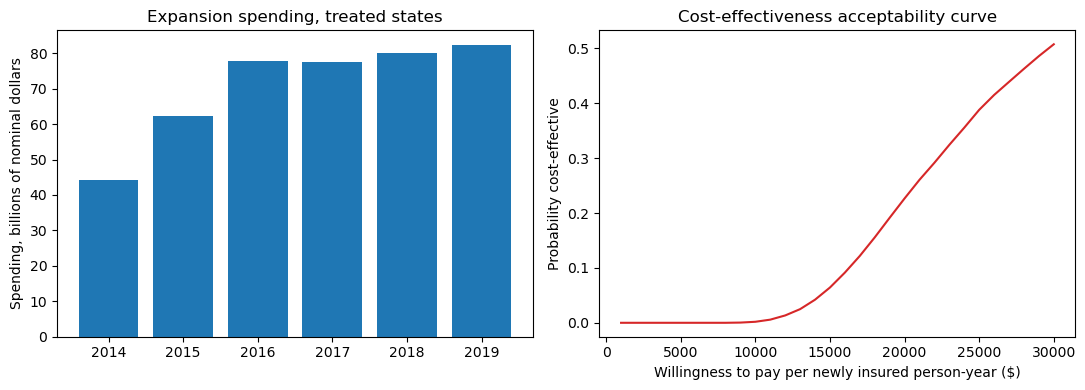

In [9]:
"""The ratio and its probabilistic sensitivity."""
lower, upper, headline = totals["lower (newly eligible only)"], totals["headline"], totals["headline"]
ratio = cea.icer(headline, person_years, 0.0, 0.0)
print(f"cost per newly insured person-year, headline: ${ratio.ratio:,.0f}  (status: {ratio.status})")
for name, value in totals.items():
    print(f"  {name:30s}: ${value / person_years:,.0f}")
print(f"  upper bound, counting only the 35-64 effect (19-64 cost over the 35-64 person-years): "
      f"${headline / (-att_c01 / 100 * float(pop_35_year.loc[POST].sum())):,.0f}")

mid = 0.5 * (lower + upper)
dc, de = cea.psa_normal(mid, (upper - lower) / (2 * 1.96), person_years, person_years_se, correlation=0.0, n=N_DRAWS, seed=SEED)
positive = de > 0
p_not_positive = float(np.mean(~positive))
print(f"draws: {N_DRAWS:,}; seed {SEED}; share of draws in which the effect is not positive: {p_not_positive:.4f}")
EXCLUDES_ZERO = lo_e > 0
if EXCLUDES_ZERO:
    q = np.quantile(dc[positive] / de[positive], [0.025, 0.5, 0.975])
    print(f"95% interval of the cost per newly insured person-year: [${q[0]:,.0f}, ${q[2]:,.0f}] (median ${q[1]:,.0f})")
else:
    print("The 95% interval of the effect includes zero, so the cost per newly insured person is not bounded: the plan reports no interval.")

curve = cea.ceac(dc, de, THRESHOLDS)
for target in (0.5, 0.9):
    reached = THRESHOLDS[curve.probability >= target]
    print(f"probability that the spending is worth the added coverage reaches {target:.0%} at ${int(reached[0]):,}" if reached.size
          else f"probability does not reach {target:.0%} by ${int(THRESHOLDS[-1]):,}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(table.index.astype(str), table["spending"] / 1e9, color="tab:blue")
axes[0].set_ylabel("Spending, billions of nominal dollars")
axes[0].set_title("Expansion spending, treated states")
axes[1].plot(THRESHOLDS, curve.probability, color="tab:red")
axes[1].set_xlabel("Willingness to pay per newly insured person-year ($)")
axes[1].set_ylabel("Probability cost-effective")
axes[1].set_title("Cost-effectiveness acceptability curve")
plt.tight_layout()
plt.show()

In [10]:
"""The decision rule from the plan, applied as written."""
print(f"Headline: ${ratio.ratio:,.0f} per newly insured person-year (nominal, gross), from ${headline / 1e9:,.1f} billion over {person_years / 1e6:,.2f} million person-years.")
print(f"Effect interval excludes zero (the plan's condition for reporting an interval): {EXCLUDES_ZERO}.")
print(f"Checks: reconciliation {RECONCILES}; no negative annual total {NO_NEGATIVE_YEAR}; sign agrees with C01 {SIGN_AGREES}.")
if not (RECONCILES and NO_NEGATIVE_YEAR and SIGN_AGREES):
    print("At least one check fails: the failure is reported here and the headline and the rules are unchanged.")

Headline: $33,957 per newly insured person-year (nominal, gross), from $424.1 billion over 12.49 million person-years.
Effect interval excludes zero (the plan's condition for reporting an interval): False.
Checks: reconciliation True; no negative annual total True; sign agrees with C01 True.


## Limitations

- **Gross, not net.** The cost is gross public spending on the expansion population. It leaves out offsets that would lower the net cost: reduced
  uncompensated care, state savings on programmes the newly covered would otherwise have used, and any tax or employment effects. It also leaves out
  administrative cost, which would raise it. The omissions of offsets mean the gross figure **overstates** the net cost per newly insured person; the
  omission of administrative cost pushes the other way.
- **Cost per newly insured, not per enrollee.** The spending includes people who would have been insured anyway; it is part of the gross cost, which
  is what makes the ratio a cost per added insured person rather than per enrolled one.
- **Nominal dollars, no discounting.** Costs from 2014 and 2019 are added as they were reported (discounting is E02).
- **Unreported quarters make the cost a lower bound.** The cost step prints how many treated state-quarters are blank or zero; none is imputed.
- **One average effect for every year.** Coverage grew over 2014 and 2015, so the early years' cost per person is overstated and the later years'
  understated by this simplification.
- **Different populations.** The spending is for the expansion group as CMS defines it and the effect is for all adults 19 to 64; they overlap but are
  not identical.
- **The effect rests on parallel trends.** It is C01's design on a different age range, with the same argument and the same caveats (early-expanding
  states in the treated group, 35 clusters). Inference is cluster-robust with the t distribution; the probabilistic analysis treats the effect and the cost
  range as independent normal draws, a stated input and not a model of the data.
- **Withheld cells.** The client withholds cells under 10 records; the retrieval step prints the share. Nothing was recoded or imputed.
- **Departure from the plan.** The analysis did not depart from the pre-registered plan in the cost source, the rules, the effect design, the checks or the
  reporting rule. The plan itself departs from "use C01's ATT" by re-estimating its design on ages 19 to 64, for the reason given under Data Provenance;
  that was written before the cost table was built.

## Key Takeaways

1. A cost-effectiveness ratio is only as good as the match between the people the cost covers and the people the effect covers; here that meant
   re-estimating the effect for the whole expansion age range.
2. Government expenditure files carry negative adjustments, blanks and zeros that mean different things; the notebook counts them and does not repair them.
3. Uncertainty comes from both sides of the ratio. When the effect's interval includes zero the ratio is unbounded, and the plan says to report that rather
   than a number.
4. Gross cost per newly insured person overstates the net cost, because the offsets are omitted; the notebook names them and the direction of the bias.

## Exercises

1. Replace the constant average effect with one effect per year from an event study. How does the cost per newly insured person in 2014 compare with 2019?
2. Use the federal share instead of the total and say whose cost per newly insured person that is.
3. Drop the treated state with the largest spending and re-estimate. Does the ratio move more through the cost or through the effect?
4. Add 20 per cent to the cost for administration. Which direction does it move the ratio, and does it change the conclusion about willingness to pay?

## References

Author, year and venue as recalled; **not verified against the published record in this build**.

- Drummond et al., *Methods for the Economic Evaluation of Health Care Programmes*, Oxford University Press.
- Briggs, Claxton and Sculpher, *Decision Modelling for Health Economic Evaluation*, Oxford University Press.
- Fenwick, Claxton and Sculpher (2001), *Representing Uncertainty: The Role of Cost-Effectiveness Acceptability Curves*, Health Economics.
- Centers for Medicare & Medicaid Services, *Medicaid CMS-64 New Adult Group Expenditures* (see `data/policy/medicaid/SOURCES.md`).
- U.S. Census Bureau, American Community Survey PUMS documentation and data dictionary, 2012-2019.